# 01 · The data

Both datasets are Walmart sales, at very different grains:

- **M5** (Kaggle, 2020): daily units for 3,049 products in 10 stores, 30,490 item × store
  series over 1,941 days. Forecast 28 days.
- **Walmart Store Sales** (Kaggle, 2014): weekly dollars for 45 stores × ~80 departments,
  3,331 series. Forecast 39 weeks.

This notebook reads the raw files (`python scripts/download_data.py --dataset all`).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "scripts"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from forecasting.viz import plots

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
%matplotlib inline
%config InlineBackend.figure_format = "png"

## M5

In [2]:
raw = ROOT / "data" / "raw" / "m5"
sales = pd.read_csv(raw / "sales_train_evaluation.csv")
calendar = pd.read_csv(raw / "calendar.csv").iloc[:1941]
units = sales.filter(like="d_").to_numpy()
dates = pd.to_datetime(calendar["date"])

span = f"{dates.min():%Y-%m-%d} to {dates.max():%Y-%m-%d}"
print(f"{units.shape[0]:,} series x {units.shape[1]:,} days, {span}")
print(
    sales.groupby("state_id")["store_id"].nunique().rename("stores").to_dict(),
    f"{sales['item_id'].nunique():,} items, {sales['dept_id'].nunique()} departments",
)

30,490 series x 1,941 days, 2011-01-29 to 2016-05-22
{'CA': 4, 'TX': 3, 'WI': 3} 3,049 items, 7 departments


### Most days sell nothing

Many items enter the data years after it starts, so zeros before an item's first sale are
not demand. Counting from each item's first sale, about 60% of days still sell zero. This is
what makes M5 hard, and why MASE is misleading on it (see notebook 03).

zero days, all:                 68.0%


zero days, after the first sale: 59.5%
items first selling over a year in: 44.0%


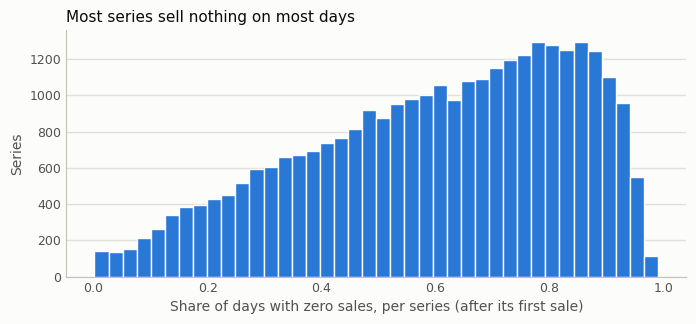

In [3]:
first_sale = (units > 0).argmax(axis=1)
live = np.arange(units.shape[1])[None, :] >= first_sale[:, None]
print(f"zero days, all:                 {(units == 0).mean():.1%}")
print(f"zero days, after the first sale: {((units == 0) & live).sum() / live.sum():.1%}")
print(f"items first selling over a year in: {(first_sale > 365).mean():.1%}")

zero_rate = ((units == 0) & live).sum(axis=1) / live.sum(axis=1)
fig, ax = plt.subplots(figsize=(8, 3.2), facecolor=plots.SURFACE)
plots.style_axes(ax, grid_axis="y")
ax.hist(zero_rate, bins=40, color=plots.BLUE, edgecolor=plots.SURFACE, linewidth=1)
ax.set_xlabel("Share of days with zero sales, per series (after its first sale)", color=plots.INK_2)
ax.set_ylabel("Series", color=plots.INK_2)
ax.set_title("Most series sell nothing on most days", loc="left", color=plots.INK, fontsize=11)
plt.show()

### Total sales: growth, a weekly cycle, and Christmas

Total sales grow about 50% over the five years. Weekends sell about 20% above the weekly
average. Every Christmas Day the stores are closed, so the total drops to almost zero.

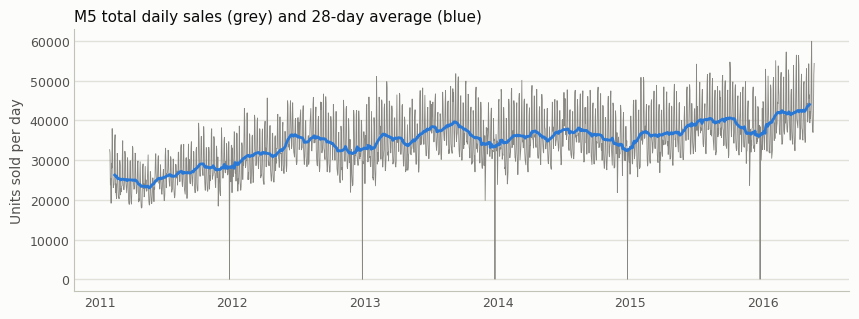

lowest days: {Timestamp('2012-12-25 00:00:00'): 11, Timestamp('2011-12-25 00:00:00'): 13, Timestamp('2015-12-25 00:00:00'): 14, Timestamp('2013-12-25 00:00:00'): 20, Timestamp('2014-12-25 00:00:00'): 20}
last year vs first year: 1.51x
{'Wednesday': 0.87, 'Thursday': 0.88, 'Tuesday': 0.88, 'Monday': 0.96, 'Friday': 1.0, 'Sunday': 1.2, 'Saturday': 1.21}


In [4]:
total = pd.Series(units.sum(axis=0), index=dates)
fig, ax = plt.subplots(figsize=(10, 3.4), facecolor=plots.SURFACE)
plots.style_axes(ax, grid_axis="y")
ax.plot(total.index, total.to_numpy(), color=plots.MUTED, linewidth=0.6)
ax.plot(total.index, total.rolling(28, center=True).mean(), color=plots.BLUE, linewidth=2)
ax.set_ylabel("Units sold per day", color=plots.INK_2)
ax.set_title(
    "M5 total daily sales (grey) and 28-day average (blue)",
    loc="left",
    color=plots.INK,
    fontsize=11,
)
plt.show()

print("lowest days:", total.nsmallest(5).to_dict())
print(f"last year vs first year: {total.iloc[-365:].mean() / total.iloc[:365].mean():.2f}x")
weekday = total.groupby(total.index.day_name()).mean()
print((weekday / weekday.mean()).round(2).sort_values().to_dict())

### What sells, and what moves it

Food is about two thirds of units. SNAP days (food-stamp payments, which differ by state)
lift California's sales by about 8%, which is why the event and SNAP features help (notebook 03).

In [5]:
last_year = sales.filter(like="d_").columns[-365:]
print(
    (sales.groupby("cat_id")[last_year].sum().sum(axis=1) / sales[last_year].sum().sum())
    .round(3)
    .to_dict()
)

ca = units[(sales["state_id"] == "CA").to_numpy()].sum(axis=0)
snap = calendar["snap_CA"].to_numpy() == 1
print(f"CA sales on SNAP days vs other days: {ca[snap].mean() / ca[~snap].mean():.3f}x")

{'FOODS': 0.659, 'HOBBIES': 0.098, 'HOUSEHOLD': 0.243}
CA sales on SNAP days vs other days: 1.080x


## Walmart

In [6]:
raw = ROOT / "data" / "raw" / "walmart"
train = pd.read_csv(raw / "train.csv", parse_dates=["Date"])
features = pd.read_csv(raw / "features.csv", parse_dates=["Date"])
print(
    f"{len(train):,} rows, {train['Store'].nunique()} stores, "
    f"{train.groupby(['Store', 'Dept']).ngroups:,} store x department series, "
    f"{train['Date'].min():%Y-%m-%d} to {train['Date'].max():%Y-%m-%d}"
)
print(f"rows with negative sales (returns): {(train['Weekly_Sales'] < 0).sum():,}")
print(f"MarkDown data starts: {features.loc[features['MarkDown1'].notna(), 'Date'].min():%Y-%m-%d}")

421,570 rows, 45 stores, 3,331 store x department series, 2010-02-05 to 2012-10-26
rows with negative sales (returns): 1,285
MarkDown data starts: 2011-11-11


### Thanksgiving and Christmas dominate

The week before Christmas sells about 1.7x a typical week and Thanksgiving week about 1.4x,
and Walmart's metric (WMAE) counts holiday weeks 5x. Note the orange dots: the dataset's
holiday flag marks the week *after* Christmas, not the peak week, which is one reason the
benchmark adds its own Christmas alignment (SNaive-xmas and holiday features). Kaggle never released its test answers, so the benchmark tests
on Kaggle's calendar one year earlier: train to 2011-10-28, forecast 2011-11-04 to 2012-07-27.
The MarkDown columns only start in November 2011, so they are empty for the whole training
window and are dropped for the neural models.

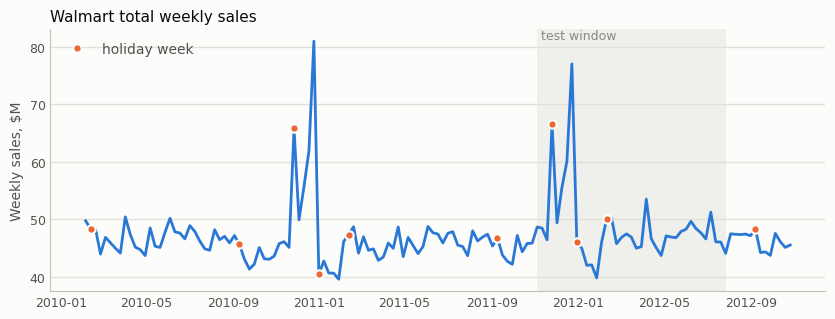

{Timestamp('2010-12-24 00:00:00'): 1.75, Timestamp('2011-12-23 00:00:00'): 1.67, Timestamp('2011-11-25 00:00:00'): 1.44, Timestamp('2010-11-26 00:00:00'): 1.42}


In [7]:
weekly = train.groupby("Date")["Weekly_Sales"].sum()
holidays = train.groupby("Date")["IsHoliday"].first()
fig, ax = plt.subplots(figsize=(10, 3.4), facecolor=plots.SURFACE)
plots.style_axes(ax, grid_axis="y")
ax.axvspan(
    pd.Timestamp("2011-11-04"),
    pd.Timestamp("2012-07-27"),
    color=plots.GRID,
    alpha=0.45,
    linewidth=0,
)
ax.plot(weekly.index, weekly / 1e6, color=plots.BLUE, linewidth=2)
ax.plot(
    weekly.index[holidays],
    weekly[holidays] / 1e6,
    "o",
    color=plots.ORANGE,
    markersize=6,
    markeredgecolor=plots.SURFACE,
    markeredgewidth=1.5,
    label="holiday week",
)
ax.text(
    pd.Timestamp("2011-11-04"),
    1.0,
    " test window",
    va="top",
    color=plots.MUTED,
    fontsize=9,
    transform=ax.get_xaxis_transform(),
)
ax.set_ylabel("Weekly sales, $M", color=plots.INK_2)
ax.legend(frameon=False, labelcolor=plots.INK_2)
ax.set_title("Walmart total weekly sales", loc="left", color=plots.INK, fontsize=11)
plt.show()
print((weekly.nlargest(4) / weekly.median()).round(2).to_dict())